# WMS `.rpt` extracts — EDA, validation, cleaning

Nineteen SQL Server extracts from wh1, December 2025. Parsing, validation and
cleaning live in the `wms_rpt` package alongside this notebook, with the test
suite under `tests/`. This notebook runs the pipeline and shows the
distributions the register decisions rest on.

```
wms_rpt/
├── reader.py       # fixed-width parse, wrapped lines, row-count checksum
├── schema.py       # table keys, join aliases, load config
├── validation.py   # structural / referential / WMS-domain checks
├── picks.py        # spine, labels, cobot attachment, sku_to_itemid
├── tasks.py        # cobot JSON explosion and reconciliation
├── rollup.py       # window aggregation and window labels
└── cleaning.py     # renames, evidenced drops, flags, jsonmsg expansion
```

Domain constraints encoded here, with evidence in the register: cleartext
extracts and retired crosswalks (D86, D100), `Temp*` badge reuse (D87),
picking / pick_tickets export fan-out (D92), workers checksum (D95),
picker-only roster (D96), SKU prefix vs bare itemid (D97), `exc_short` as a
subset of `did_mismatch` (D99).

CKs is a shortage log — found is strictly less than expected in every row.

## 0. Environment

In [1]:
# One-time setup for a fresh machine. Leave these commented out on a machine
# that already has the packages; uncomment and run once on a new one.
# !python -m pip install --upgrade pip
# %pip install -q fg-data-profiling pandas numpy matplotlib pyarrow watermark pytest
# %pip install ipywidgets

In [2]:
# Print which Python and package versions this run used, so I can tell later
# which machine and environment produced the outputs. Uses the watermark
# extension when it is installed and falls back to printing versions by hand.
try:
    %load_ext watermark
    %watermark -v -m -p pandas,numpy,matplotlib,pyarrow
except ModuleNotFoundError:
    import platform, sys
    import matplotlib, numpy, pandas, pyarrow
    print("watermark not installed (pip install watermark for the full report)\n")
    print(f"Python   : {sys.version.split()[0]}")
    print(f"Platform : {platform.platform()}")
    for m in (pandas, numpy, matplotlib, pyarrow):
        print(f"{m.__name__:<10}: {m.__version__}")

Python implementation: CPython
Python version       : 3.12.10
IPython version      : 9.15.0

pandas    : 2.3.3
numpy     : 2.3.5
matplotlib: 3.10.0
pyarrow   : 25.0.0

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 186 Stepping 2, GenuineIntel
CPU cores   : 16
Architecture: 64bit



In [3]:
# Imports, the random seed and the plot defaults. The seed is fixed at 29 so
# anything random comes out the same every run. The wms_rpt package sits next
# to this notebook, so I add the current folder to the path and pull the
# reader, validator and cleaner in from there.
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))

from wms_rpt import (
    HASH_COLS, USECOLS, Validator, clean_tables, coerce, read_rpt, table_key,
)

RANDOM_STATE = 29
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 120)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [4]:
# Find the folder of .rpt extracts and create the output folders. I can set
# RPT_DIR by hand to skip the search. The search is deliberately not recursive,
# so it can never wander into data/raw/archive_hashed and pick up the old
# hashed extracts (D100).
RPT_DIR: Path | None = None

_CANDIDATES = [Path("data/raw"), Path("data"), Path("."), Path("../data"),
               Path.home() / "Documents" / "wms_data", Path.home() / "Downloads"]
if RPT_DIR is None:
    for _c in _CANDIDATES:
        if _c.is_dir() and any(_c.glob("*.rpt")):
            RPT_DIR = _c
            break
    else:
        raise FileNotFoundError(
            "No .rpt files found in: "
            + ", ".join(str(c) for c in _CANDIDATES)
            + " — set RPT_DIR explicitly above.")
    # This assert only matters when I let the search find the folder. Without it
    # an empty data/raw would quietly fall through to the notebook folder and I
    # would be parsing whatever .rpt happened to be lying around there.
    assert RPT_DIR == Path("data/raw"), \
        f"RPT_DIR auto-resolved to {RPT_DIR}, expected data/raw"

RAW_DIR, CLEAN_DIR, REPORT_DIR = Path("data/raw_parquet"), Path("data/clean"), Path("reports")
for d in (RAW_DIR, CLEAN_DIR, REPORT_DIR):
    d.mkdir(parents=True, exist_ok=True)

rpt_files = sorted(RPT_DIR.glob("*.rpt"))
print(f"{len(rpt_files)} files in {RPT_DIR.resolve()}\n")
for f in rpt_files:
    print(f"  {table_key(f):<22} {f.stat().st_size/1e6:>8.1f} MB")

19 files in C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1\data\raw

  checker_ck_rates            0.0 MB
  cks                         6.1 MB
  cobot_jsons_overflow     2996.3 MB
  cobot_jsons              1748.0 MB
  hashed_badges               0.5 MB
  hashed_slots                2.5 MB
  item_features              30.7 MB
  items                      31.8 MB
  pick_tickets             3616.8 MB
  picking                 78672.7 MB
  picktickettimer             3.8 MB
  putaways                    8.4 MB
  shippingintent_sku         46.2 MB
  slot_audit_history         13.5 MB
  slot_event_sources          0.0 MB
  slot_features             151.5 MB
  slot_history              615.1 MB
  slots                       9.3 MB
  workers                     0.1 MB


## 1. Ingest

`read_rpt` streams each file and keeps the `(N rows affected)` footer as a
checksum; `coerce` types every column and logs the decision.

The checksum must read OK. A mismatch means the parse dropped or invented
rows, which is how 36 `Temp*` badges were lost from workers (D95).

In [5]:
# Parse every extract, give each column a proper type, and save the rows as
# exported to data/raw_parquet. For each file I print rows x columns, memory,
# and whether my row count matches the "(N rows affected)" footer SQL Server
# wrote at the bottom. That checksum has to say OK — a mismatch means the
# parser dropped or invented rows, which is exactly how 36 Temp* badges went
# missing from workers once (D95).
tables, layouts, type_logs, subset_loaded = {}, {}, {}, {}

for f in rpt_files:
    key = table_key(f)
    cols = USECOLS.get(key)
    if cols:
        from wms_rpt import sniff_layout
        subset_loaded[key] = len(sniff_layout(f).names) - len(cols)
    df, lay = read_rpt(f, usecols=cols, categoricals=HASH_COLS)
    df2, tlog = coerce(df)
    tables[key], layouts[key], type_logs[key] = df2, lay, tlog
    tables[key].to_parquet(RAW_DIR / f"{key}.parquet", index=False)
    ok = ("OK" if lay.declared_rows in (None, len(df2))
          else f"MISMATCH (declared {lay.declared_rows:,})")
    extra = f"  [{lay.notes[-1]}]" if lay.stitched_lines else ""
    print(f"{key:<22} {len(df2):>9,} x {df2.shape[1]:<3} "
          f"{df2.memory_usage(deep=True).sum()/1e6:>7.1f} MB  checksum={ok}{extra}")

checker_ck_rates             157 x 3       0.0 MB  checksum=OK
cks                       13,665 x 17      5.4 MB  checksum=OK
cobot_jsons_overflow      60,921 x 8     734.0 MB  checksum=OK
cobot_jsons            1,212,895 x 9    1597.9 MB  checksum=OK
hashed_badges              6,582 x 2       1.6 MB  checksum=OK
hashed_slots              31,465 x 2       7.5 MB  checksum=OK
item_features            188,749 x 6      23.1 MB  checksum=OK
items                    407,501 x 2     105.5 MB  checksum=OK
pick_tickets             854,429 x 9      89.0 MB  checksum=OK
picking                17,775,003 x 9    1006.4 MB  checksum=OK
picktickettimer           43,698 x 3       5.6 MB  checksum=OK
putaways                  57,593 x 10      9.1 MB  checksum=OK
shippingintent_sku       942,187 x 2     125.1 MB  checksum=OK
slot_audit_history        55,186 x 14      8.8 MB  checksum=OK
slot_event_sources            34 x 2       0.0 MB  checksum=OK
slot_features            558,335 x 12    153.1 MB  che

In [6]:
# Show the column-typing decisions for one table. Every table has a log like
# this; change the key to look at a different one.
print(type_logs["cks"].to_string(index=False))

            column             decision     n
             ck_id               string 12448
shippingintent_nbr category (hashed id) 12448
             ck_ts   datetime (0% null) 13665
  cker_employee_id category (hashed id)    81
       colorresult             category     4
         tsstarted   datetime (0% null) 13665
               sku category (hashed id)  5658
       ck_quantity                  int 13665
            slotid category (hashed id)  7386
 quantityfoundbyck                  int 13665
       iswrongitem                  int 13665
     pickticket_id category (hashed id)  5209
          tspicked  datetime (93% null)   918
picker_employee_id category (hashed id)   112
      slotlocation category (hashed id)  3934
     pick_quantity                  int  6164
    quantitypicked                  int   918


## 2. EDA — one question per figure

The automated profiler in Appendix A is for first contact with new or changed
extracts.

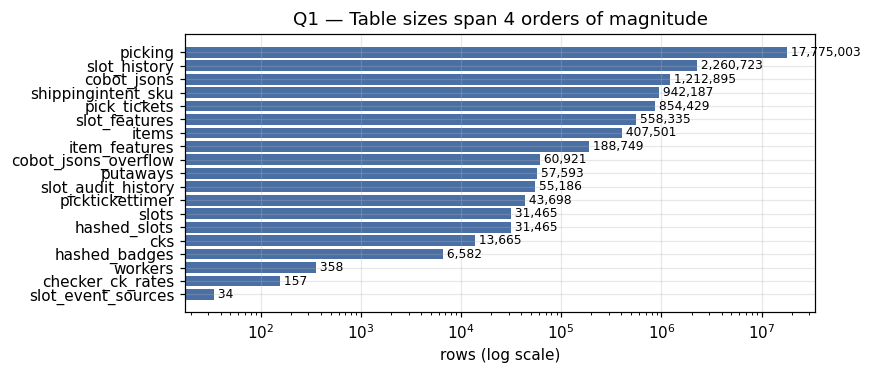

In [7]:
# Q1 — how big is each table? Row counts on a log scale, because the tables
# run from a few hundred rows to tens of millions.
fig, ax = plt.subplots(figsize=(8, 3.5))
sizes = pd.Series({k: len(v) for k, v in tables.items()}).sort_values()
ax.barh(sizes.index, sizes.values, color="#4a6fa5")
ax.set_xscale("log")
ax.set_xlabel("rows (log scale)")
ax.set_title("Q1 — Table sizes span 4 orders of magnitude")
for i, v in enumerate(sizes.values):
    ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout(); plt.show()

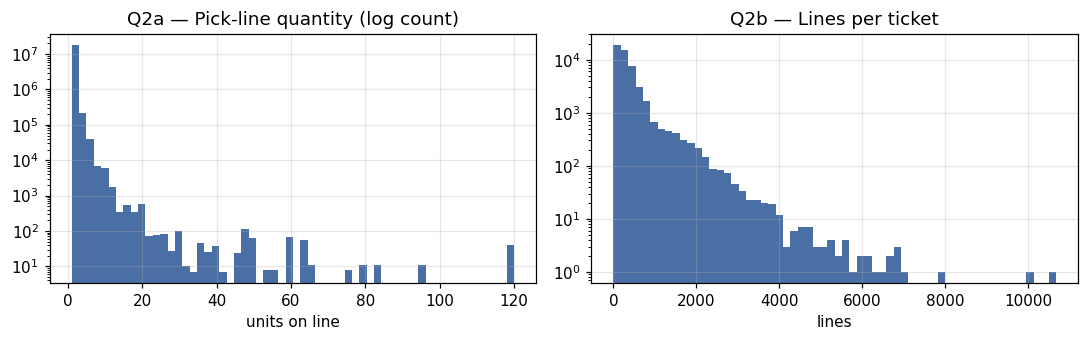

quantity: median 1.0, p99 3, max 120  |  lines/ticket: median 238, max 10664


In [8]:
# Q2 — how long are the tails? Left: units per pick line. Right: lines per
# ticket. Log y-axis so the rare big values still show. Then the median, 99th
# percentile and max in text.
p = tables["picking"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
p["quantity"].astype(float).hist(bins=60, ax=axes[0], color="#4a6fa5")
axes[0].set_yscale("log")
axes[0].set(title="Q2a — Pick-line quantity (log count)", xlabel="units on line")
per_ticket = p.groupby("pickticket_id", observed=True).size()
per_ticket.hist(bins=60, ax=axes[1], color="#4a6fa5")
axes[1].set_yscale("log")
axes[1].set(title="Q2b — Lines per ticket", xlabel="lines")
plt.tight_layout(); plt.show()
print(f"quantity: median {p.quantity.median()}, p99 {p.quantity.quantile(.99):.0f}, "
      f"max {p.quantity.max()}  |  lines/ticket: median {per_ticket.median():.0f}, "
      f"max {per_ticket.max()}")

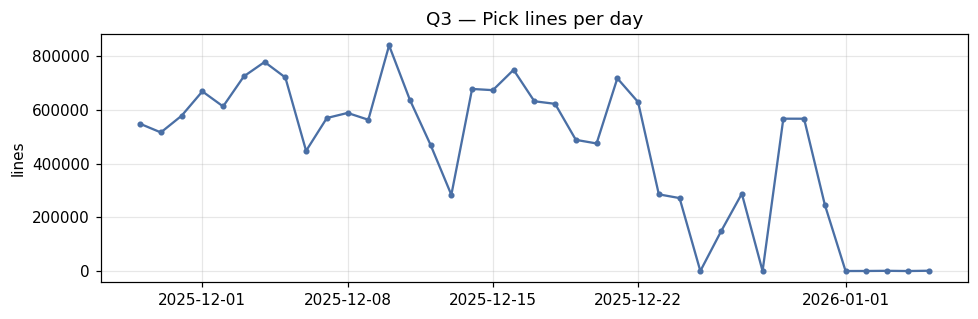

weekday median 567,335 vs weekend median 461,294


In [9]:
# Q3 — is daily volume steady across December, or would month-end throw off
# a time-based split? Pick lines per day, then weekday vs weekend medians.
daily = (p.set_index("tspicked").resample("D").size())
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(daily.index, daily.values, marker="o", ms=3, color="#4a6fa5")
ax.set(title="Q3 — Pick lines per day", ylabel="lines")
plt.tight_layout(); plt.show()
print(f"weekday median {daily[daily.index.dayofweek < 5].median():,.0f} vs "
      f"weekend median {daily[daily.index.dayofweek >= 5].median():,.0f}")

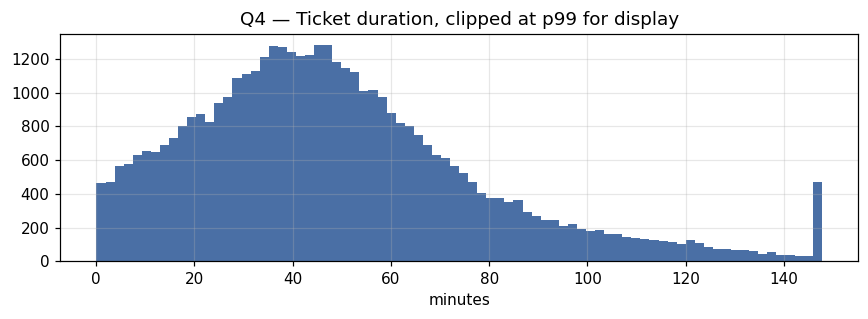

median 44.9 min | p90 88 | p99 148 | max 66 h (full values retained in the data)


In [10]:
# Q4 — how long does a ticket take? Minutes from start to end, clipped at the
# 99th percentile just for the picture (the real values stay in the data).
tm = tables["picktickettimer"]
dur_min = (tm.tsended - tm.tsstarted).dt.total_seconds() / 60
fig, ax = plt.subplots(figsize=(8, 3))
dur_min.clip(upper=dur_min.quantile(0.99)).hist(bins=80, ax=ax, color="#4a6fa5")
ax.set(title="Q4 — Ticket duration, clipped at p99 for display",
       xlabel="minutes")
plt.tight_layout(); plt.show()
print(f"median {dur_min.median():.1f} min | p90 {dur_min.quantile(.9):.0f} | "
      f"p99 {dur_min.quantile(.99):.0f} | max {dur_min.max()/60:.0f} h "
      f"(full values retained in the data)")

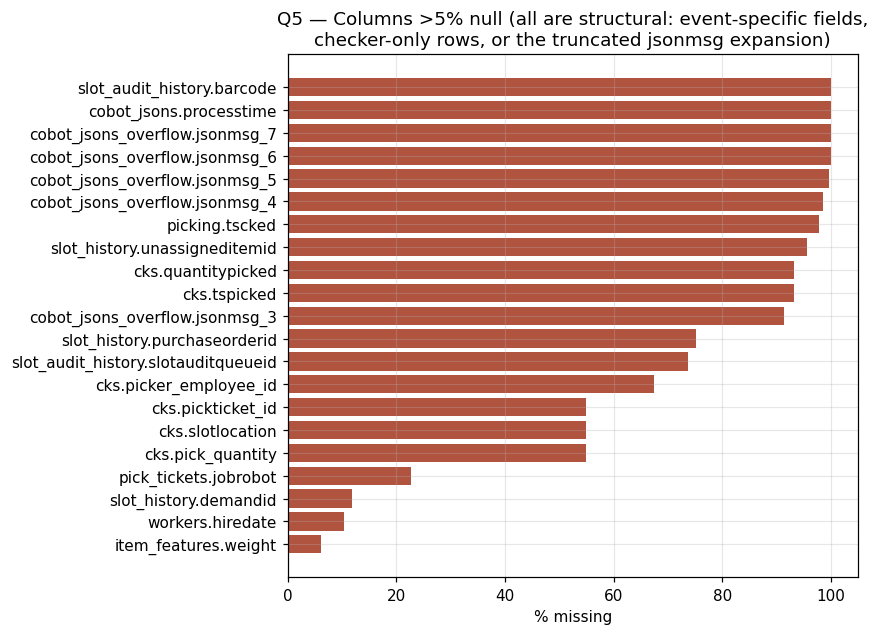

In [11]:
# Q5 — which columns are mostly empty? Every column that is more than 5% null.
# All of them are empty for structural reasons: fields that only apply to some
# event types, checker-only rows, or the truncated jsonmsg chunks.
miss = (pd.concat({k: v.isna().mean() for k, v in tables.items()})
          .rename_axis(["table", "column"]).rename("p_missing")
          .loc[lambda s: s > 0.05].sort_values())
fig, ax = plt.subplots(figsize=(8, max(2.5, 0.28 * len(miss))))
labels = [f"{t}.{c}" for t, c in miss.index]
ax.barh(labels, miss.values * 100, color="#b0533f")
ax.set_xlabel("% missing")
ax.set_title("Q5 — Columns >5% null (all are structural: event-specific fields,\n"
             "checker-only rows, or the truncated jsonmsg expansion)")
plt.tight_layout(); plt.show()

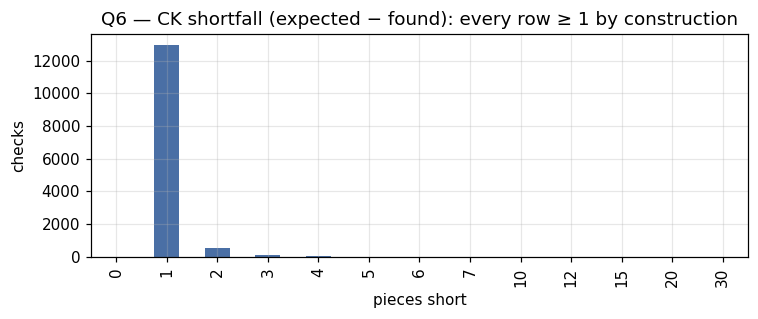

95% of shortages are a single piece; max shortfall 30


In [12]:
# Q6 — when a checker finds a shortage, how big is it? Expected minus found,
# in pieces. Every row is at least 1 because cks only ever logs shortages.
ck = tables["cks"]
shortfall = (pd.to_numeric(ck.ck_quantity, errors="coerce")
             - pd.to_numeric(ck.quantityfoundbyck, errors="coerce"))
fig, ax = plt.subplots(figsize=(7, 3))
shortfall.value_counts().sort_index().head(15).plot.bar(ax=ax, color="#4a6fa5")
ax.set(title="Q6 — CK shortfall (expected − found): every row ≥ 1 by construction",
       xlabel="pieces short", ylabel="checks")
plt.tight_layout(); plt.show()
print(f"{(shortfall == 1).mean():.0%} of shortages are a single piece; "
      f"max shortfall {shortfall.max():.0f}")

## 3. Validate

Rules live in `wms_rpt/validation.py`. One finding is by design and will not
clear: checker badges absent from the picker-only roster (D96).

`wms_divergence` also emits zero now its crosswalk is retired (D100), but that
is no longer reported as a standing finding — the label came out of
`LABEL_COLS` in 1.6.0 rather than being tolerated indefinitely (D138).

In [13]:
# Run the four validation passes from wms_rpt/validation.py: structure (row
# counts, empty columns), referential (do child keys exist in the parent
# table), sentinel values, and the WMS business rules. Then count findings by
# severity and show the errors and warnings. One finding will never clear:
# checker badges are not in the picker-only roster, by design (D96).
validator = Validator()
validator.structural(tables, layouts, subset_loaded)
keymap = validator.referential(tables)
validator.sentinels(tables, keymap, downstream={
    ("shippingintent_sku", "sku"):
        ("picking", "shippingintentline_id", "shippingintentline_id"),
})
validator.domain(tables)

fdf = validator.to_frame()
print(f"{(fdf.severity == 'error').sum()} errors | "
      f"{(fdf.severity == 'warn').sum()} warnings | "
      f"{(fdf.severity == 'info').sum()} info")
fdf[fdf.severity.isin(["error", "warn"])].head(40)

9 errors | 65 warnings | 36 info


,table,check,severity,detail,n_affected
0,cobot_jsons,all_null,error,'processtime' entirely null,1212895
1,picking,tscked_semantics,error,tsCKed present in only 1.4% of rows and preced...,217516
2,slot_audit_history,all_null,error,'barcode' entirely null,55186
3,slot_history,implausible_qty,error,'physicalinventory': 420 rows (0.02%) in non-b...,420
4,slot_history,implausible_qty,error,'virtualinventory': 250 rows (0.01%) in non-bu...,250
5,slot_audit_history,implausible_qty,error,'quantity': 12 rows (0.02%),12
6,slot_audit_history,implausible_qty,error,'previousquantity': 10 rows (0.02%),10
7,workers,negative_tenure,error,'tenure_wks': 1 rows (0.28%),1
8,putaways,implausible_qty,error,'origianlqty': 1 rows (0.00%),1
9,picking,high_missing,warn,'tscked' 97.9% null,17397706


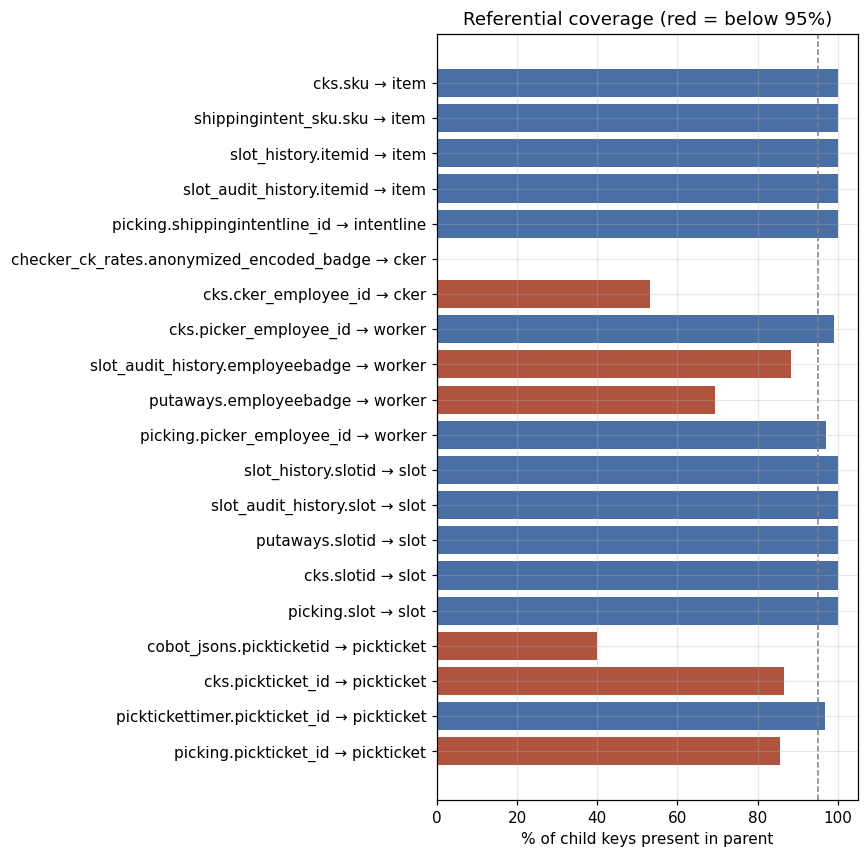

In [14]:
# Referential coverage picture — for each child-table key, what share of its
# values exist in the parent table. Red bars are below 95%; that is where I
# look for orphan keys.
kv = keymap.dropna(subset=["coverage"]).query("~is_parent")
fig, ax = plt.subplots(figsize=(8, 0.32 * len(kv) + 1.5))
labels = [f"{r.table}.{r.column} → {r.entity}" for r in kv.itertuples()]
colors = ["#b0533f" if c < 0.95 else "#4a6fa5" for c in kv.coverage]
ax.barh(labels, kv.coverage * 100, color=colors)
ax.axvline(95, color="grey", ls="--", lw=1)
ax.set_xlabel("% of child keys present in parent")
ax.set_title("Referential coverage (red = below 95%)")
plt.tight_layout(); plt.show()

In [15]:
# D92: the picking export repeats every pick line about 24 times. That is a
# bug in the SQL that produced the extract, not in my parser. I collapse it
# here, AFTER validation, so the structural check still compares what I parsed
# against the footer count, and data/raw_parquet keeps the fan-out as evidence.
# The assert pins the expected 733,787 distinct lines — if a re-pull ever fixes
# the SQL this fires and I know to retire the step.
_pre = len(tables["picking"])
tables["picking"] = (tables["picking"]
                     .drop_duplicates(["pickticket_id", "shippingintentline_id"])
                     .reset_index(drop=True))
_post = len(tables["picking"])
assert _post == 733_787, f"expected 733,787 distinct pick lines, got {_post:,}"
print(f"picking  {_pre:,} -> {_post:,}  ({1 - _post/_pre:.1%} removed, ratio {_pre/_post:.2f})")

picking  17,775,003 -> 733,787  (95.9% removed, ratio 24.22)


In [16]:
# Sanity check on dates after the fan-out collapse: how many December pick
# lines do I have against the 654,005 I expected, and where do the extra
# lines sit?
p = tables["picking"]
dec = p[(p['tspicked'] >= '2025-12-01') & (p['tspicked'] < '2026-01-01')]
print(f"Dec picked lines {dec.drop_duplicates(['pickticket_id','shippingintentline_id']).shape[0]:,}  target 654,005")

# Count lines by month — the spill outside December is the late-November and
# early-January edges.
print(p['tspicked'].dt.to_period('M').value_counts().sort_index())

# Are the edge rows whole tickets that sit outside December, or tickets that
# straddle a month boundary?
p['_m'] = p['tspicked'].dt.to_period('M')
span = p.groupby('pickticket_id', observed=False)['_m'].nunique()
print(f"tickets spanning >1 month: {(span>1).sum():,} of {len(span):,}")

# Lines with no pick time: were they still open when the extract was taken (so
# they bunch up at the end), or spread through the month? Prints the creation
# date range using whichever creation column this extract has.
u = p[p['tspicked'].isna()]
for c in ['tscreated','ts_created','tsentered']:
    if c in u: print(c, u[c].min(), u[c].max()); break

Dec picked lines 653,952  target 654,005
tspicked
2025-11     67969
2025-12    653952
2026-01        88
Freq: M, Name: count, dtype: int64
tickets spanning >1 month: 120 of 49,692


## 4. Clean

Flag rather than fix; drop only what a finding proved redundant; canonicalize
keys. Rules and rationale in `wms_rpt/cleaning.py`.

`SENTINEL_HASHES` is empty and inert since the cleartext re-pull, kept defined
so the cleaning log still records the rule (D93).

In [17]:
# Run the cleaning rules (rename, drop what a finding proved redundant, flag
# the rest), then collapse pick_tickets to one row per ticket and write the
# clean parquet files.
clean, clean_log = clean_tables(tables, subset_loaded, validator)

# pick_tickets has every ticket twice: once before the robot was assigned
# (jobrobot empty) and once after. Dropping exact duplicates does not catch
# it because the two rows differ, and a plain merge on pickticket_id would
# pick the empty or the real robot at random. I sort so the row with a robot
# comes first, keep that one, and log the step so the cleaning log stays
# complete.
_pt = clean["pick_tickets"]
_before = len(_pt)
_pt = (_pt.sort_values("jobrobot", na_position="last", kind="mergesort")
          .drop_duplicates("pickticket_id", keep="first")
          .reset_index(drop=True))
clean["pick_tickets"] = _pt
clean_log.loc[len(clean_log)] = {
    "table": "pick_tickets",
    "action": "drop_duplicates",
    "detail": ("pickticket_id, keeping non-null jobrobot: export emits each "
               "ticket twice, pre- and post-robot-assignment"),
    "n": _before - len(_pt),
}
assert _pt["pickticket_id"].is_unique, "pick_tickets not ticket-grain after collapse"

for key, d in clean.items():
    d.to_parquet(CLEAN_DIR / f"{key}.parquet", index=False)

print(clean_log.to_string(index=False))

             table           action                                                                                                                                                     detail      n
               cks      drop_column                                                                                             colorresult: deprecated by the WMS team; not used in any check      0
               cks           derive                                                             ck_shortfall_qty / ck_found_none / ck_fill_rate (no ck_found_all: it is False by construction)      3
               cks  drop_duplicates                                                                                                                        exact duplicates across all columns      1
       cobot_jsons           rename                                                                                                                          {'pickticketid': 'pickticket_id'}      0
       cob

In [18]:
# Write the three reports to reports/: the validation findings, a data
# dictionary (type, null %, distinct count for every column of every clean
# table), and the cleaning log. Runs after cleaning so the jsonmsg truncation
# finding makes it into the file.
fdf = validator.to_frame()
fdf.to_csv(REPORT_DIR / "validation_findings.csv", index=False)

dd = []
for key, d in clean.items():
    for c in d.columns:
        s = d[c]
        dd.append({"table": key, "column": c, "dtype": str(s.dtype),
                   "n_rows": len(d),
                   "pct_null": round(s.isna().mean() * 100, 2),
                   "n_distinct": int(s.nunique(dropna=True))})
pd.DataFrame(dd).to_csv(REPORT_DIR / "data_dictionary.csv", index=False)
clean_log.to_csv(REPORT_DIR / "cleaning_log.csv", index=False)
print(f"{len(fdf)} findings, {len(dd)}-column data dictionary, cleaning log "
      f"-> {REPORT_DIR.resolve()}")

110 findings, 158-column data dictionary, cleaning log -> C:\Users\barbarap\OneDrive - FRAGRANCENET\Desktop\2026-1\reports


## 5. Verify

Row and column deltas per table. No surviving numeric column may shift its
median.

In [19]:
# Before/after check per table: rows and columns removed, and whether any
# surviving numeric column changed its median. Cleaning should drop junk, not
# move distributions, so a shifted median is a red flag and the assert fails.
rows = []
for key in clean:
    raw_df, cl_df = tables[key], clean[key]
    shifted = []
    for c in set(raw_df.columns) & set(cl_df.columns):
        if (pd.api.types.is_numeric_dtype(raw_df[c])
                and pd.api.types.is_numeric_dtype(cl_df[c])):
            a, b = raw_df[c].median(), cl_df[c].median()
            if pd.notna(a) and pd.notna(b) and not np.isclose(float(a), float(b)):
                shifted.append(c)
    rows.append({"table": key, "rows_before": len(raw_df),
                 "rows_after": len(cl_df),
                 "rows_removed": len(raw_df) - len(cl_df),
                 "cols_before": raw_df.shape[1], "cols_after": cl_df.shape[1],
                 "medians_shifted": ", ".join(shifted) or "none"})
verify = pd.DataFrame(rows)

# One known exception: stripping the pick_tickets fan-out (D92) moves the
# median of `sequence`. I exempt that one column by name instead of loosening
# the assert, so any other shift still fails.
EXPECTED_SHIFTS = {("pick_tickets", "sequence")}

unexpected = [(r.table, c) for r in verify.itertuples()
              for c in r.medians_shifted.split(", ")
              if c != "none" and (r.table, c) not in EXPECTED_SHIFTS]
assert not unexpected, f"unexpected distribution shifts: {unexpected}"
verify

,table,rows_before,rows_after,rows_removed,cols_before,cols_after,medians_shifted
0,checker_ck_rates,157,157,0,3,3,none
1,cks,13665,13664,1,17,19,none
2,cobot_jsons,1212895,1212895,0,9,23,none
3,hashed_badges,6582,6565,17,2,2,none
4,hashed_slots,31465,31465,0,2,2,none
5,item_features,188749,188749,0,6,6,none
6,items,407501,407501,0,2,2,none
7,pick_tickets,854429,42477,811952,9,8,sequence
8,picking,733787,733787,0,10,10,none
9,picktickettimer,43698,43698,0,3,3,none


## Appendix A — automated profiling

For new or changed extracts only. Skipped on routine re-runs.

In [20]:
# Automated profiling report (one HTML file per clean table). Only worth
# running on a new or changed extract — set RUN_PROFILER = False on routine
# re-runs.
RUN_PROFILER = True

if RUN_PROFILER:
    import re as _re
    from ydata_profiling import ProfileReport

    for key, df in clean.items():
        try:
            src = df.copy()
            # Drop the columns that would blow the report up and tell me nothing:
            # ID-like categoricals with hundreds of levels, the jsonmsg payload columns,
            # and anything holding very long strings.
            hashy = [c for c in src.columns
                     if isinstance(src[c].dtype, pd.CategoricalDtype)
                     and src[c].nunique() > 500]
            src = src.drop(columns=hashy, errors="ignore")
            src = src.drop(columns=[c for c in src.columns
                                    if _re.fullmatch(r"jsonmsg(_\d+)?", c)])
            for c in list(src.columns):
                s = src[c].dropna().astype(str)
                if len(s) and s.str.len().max() > 1000:
                    src = src.drop(columns=c)
            if src.shape[1] == 0:
                print(f"[skip]   {key} (nothing profileable after drops)")
                continue
            ProfileReport(src, title=key, minimal=True, progress_bar=False
                          ).to_file(REPORT_DIR / f"{key}.html")
            print(f"[report] {key}")
        except Exception as e:
            # If one table cannot be profiled, log it and keep going rather than killing
            # the whole appendix.
            print(f"[FAIL]   {key}: {type(e).__name__}: {e}")
else:
    print("Profiler skipped (RUN_PROFILER = False)")

C:\Users\barbarap\AppData\Local\Temp\ipykernel_21708\484348207.py:8: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport
100%|██████████| 3/3 [00:00<?, ?it/s]


[report] checker_ck_rates


100%|██████████| 14/14 [00:00<00:00, 131.05it/s]


[report] cks


  5%|▌         | 1/20 [00:13<04:25, 13.97s/it]C:\Users\barbarap\AppData\Local\Programs\Python\Python312\Lib\site-packages\data_profiling\model\pandas\describe_date_pandas.py:57: UserWarning: Discarding nonzero nanoseconds in conversion.
  "min": pd.Timestamp.to_pydatetime(series.min()),
100%|██████████| 20/20 [00:14<00:00,  1.38it/s]


[report] cobot_jsons
[skip]   hashed_badges (nothing profileable after drops)
[skip]   hashed_slots (nothing profileable after drops)


... (18 outputs left out)

100%|██████████| 9/9 [00:00<00:00, 600.07it/s]


[report] slots


100%|██████████| 9/9 [00:00<00:00, 9011.40it/s]


[report] workers
